# Lab: Relationships Between Quantitative Features

Use a historical mammal sleep dataset to compare dreaming, non-dreaming, and total sleep. Use non-dreaming versus total sleep as the main model, then examine whether danger and predation ratings add information. Finally, investigate the nonlinear pattern between gestation time and total sleep.

Support conclusions with the plots and calculations. Explain how well a straight line follows the points and how much variation remains.

## Learning goals

- Describe whether points trend upward or downward, follow a straight or curved pattern, cluster closely around that pattern, or include unusual observations.
- Calculate correlation and interpret R-squared on the correct response scale.
- Recognize nonlinear patterns and compare original gestation with log-transformed gestation.
- Examine additional categorical features visually and compare model R-squared on the same observations.
- Check missing codes, units, category counts, and transformations.
- Distinguish improved fit to observed records from causation and performance on new data.

## The reproducible analysis workflow

1. **Question:** What do we want to learn?
2. **Data:** Which observations and features can answer it?
3. **Evidence:** What should we calculate and display?
4. **Check:** Does the result make sense in context and agree with the original records?
5. **Conclusion:** What claim is supported?
6. **Limitation:** What should we avoid concluding?

Complete each investigation in order. Use separate cells for individual operations and add cells as needed. Give figures informative titles, named colors, and axis labels with units or transformations. Use the default point transparency and line widths. `ci=None` can omit confidence bands so the patterns and group lines are easier to compare.

## Using AI tools responsibly

You may use AI to ask questions, debug code, or receive feedback. You remain responsible for understanding the code and checking every claim against the source and your output. Complete the AI-use reflection at the end.

## Dataset and context

Use the [StatLib mammal sleep data hosted by UC Berkeley](https://www.stat.berkeley.edu/~spector/s100/data/sleep.dat) and its [measurement dictionary](https://www.stat.berkeley.edu/~spector/s100/data/sleep.html). A local copy is supplied as `data/mammal_sleep.csv`.

The supplied `data/mammal_sleep.csv` contains all 62 records and 11 features, including species names and both sleep phases. One row describes a mammal species, not an individual animal or a night. The data trace to Allison and Cicchetti's 1976 study, [Sleep in mammals: ecological and constitutional correlates](https://pubmed.ncbi.nlm.nih.gov/982039/). This is a historical comparative dataset, not a random sample of all mammals; individual collection dates are not supplied.

Course preparation preserves all values and names, gives columns descriptive names, and converts the source's `-999` missing code into blank CSV fields. Use ordinary `pd.read_csv()`; blanks are recognized as missing. The terms dreaming and non-dreaming identify the study's sleep-phase measurements; they are not direct reports of an animal's subjective dream experiences.

### Data dictionary

| Feature | Meaning and units or codes |
| --- | --- |
| `species` | Species label as recorded in the historical source |
| `non_dreaming_sleep` | Non-dreaming sleep in hours per day |
| `dreaming_sleep` | Dreaming sleep in hours per day |
| `body_weight` | Body weight in kilograms |
| `brain_weight` | Brain weight in grams |
| `max_life_span` | Maximum lifespan in years |
| `gestation_time` | Gestation duration in days |
| `predation_index` | Ordered rating, 1–5: lower to higher likelihood of being preyed upon |
| `sleep_exposure_index` | Ordered rating, 1–5: more protected to more exposed sleeping conditions |
| `danger_index` | Ordered rating, 1–5: lower to higher overall danger from other animals |
| `total_sleep` | Total sleep in hours per day; sum of the two phases |

The indices are **ordinal categorical features**, even though stored as numbers. A one-point difference is not a documented equal increment of physical risk. Overall danger incorporates predation, sleep exposure, and other information, so these ratings are not independent measurements. In our models, represent rating levels as categories rather than assuming equal numerical spacing.

## Load and inspect the data

In [1]:
# Import NumPy, Pandas, Matplotlib pyplot, and Seaborn.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Read data/mammal_sleep.csv into mammals_df; blank fields are recognized as missing.
mammals_df = pd.read_csv("data/mammal_sleep.csv")

In [3]:
# Display the first five rows.
mammals_df.head()

,species,body_weight,brain_weight,non_dreaming_sleep,dreaming_sleep,total_sleep,max_life_span,gestation_time,predation_index,sleep_exposure_index,danger_index
0,African elephant,6654.000,5712.0,NaN,NaN,3.3,38.6,645.0,3,5,3
1,African giant pouched rat,1.000,6.6,6.3,2.0,8.3,4.5,42.0,3,1,3
2,Arctic Fox,3.385,44.5,NaN,NaN,12.5,14.0,60.0,1,1,1
3,Arctic ground squirrel,0.920,5.7,NaN,NaN,16.5,NaN,25.0,5,2,3
4,Asian elephant,2547.000,4603.0,2.1,1.8,3.9,69.0,624.0,3,5,4


In [4]:
# Display the last five rows.
mammals_df.tail()

,species,body_weight,brain_weight,non_dreaming_sleep,dreaming_sleep,total_sleep,max_life_span,gestation_time,predation_index,sleep_exposure_index,danger_index
57,Tree hyrax,2.000,12.3,4.9,0.5,5.4,7.5,200.0,3,1,3
58,Tree shrew,0.104,2.5,13.2,2.6,15.8,2.3,46.0,3,2,2
59,Vervet,4.190,58.0,9.7,0.6,10.3,24.0,210.0,4,3,4
60,Water opossum,3.500,3.9,12.8,6.6,19.4,3.0,14.0,2,1,1
61,Yellow-bellied marmot,4.050,17.0,NaN,NaN,NaN,13.0,38.0,3,1,1


In [5]:
# Display the shape.
mammals_df.shape

(62, 11)

In [6]:
# Use .info() to inspect the data storage types and non-missing values.
mammals_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 62 entries, 0 to 61
Data columns (total 11 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   species               62 non-null     object 
 1   body_weight           62 non-null     float64
 2   brain_weight          62 non-null     float64
 3   non_dreaming_sleep    48 non-null     float64
 4   dreaming_sleep        50 non-null     float64
 5   total_sleep           58 non-null     float64
 6   max_life_span         58 non-null     float64
 7   gestation_time        58 non-null     float64
 8   predation_index       62 non-null     int64  
 9   sleep_exposure_index  62 non-null     int64  
 10  danger_index          62 non-null     int64  
dtypes: float64(7), int64(3), object(1)
memory usage: 5.5+ KB


In [7]:
# Count missing values in every feature.
mammals_df.isnull().sum()

species                  0
body_weight              0
brain_weight             0
non_dreaming_sleep      14
dreaming_sleep          12
total_sleep              4
max_life_span            4
gestation_time           4
predation_index          0
sleep_exposure_index     0
danger_index             0
dtype: int64

**What does one row represent?**

Your answer: One row represents one mammal species, with its average sleep measurements, body and brain weight, lifespan, gestation time, and danger ratings. It is not one individual animal or one night of sleep.

**Complete the table using the data dictionary, `.info()`, and `.isnull().sum()`. For data type, use categorical or quantitative. For data storage type, report the Pandas dtype. For missing values, report the count, including 0 when none are missing.**

| Feature | Data type | Data storage type | Missing values |
| --- | --- | --- | ---: |
| `species` | categorical | object | 0 |
| `non_dreaming_sleep` | quantitative | float64 | 14 |
| `dreaming_sleep` | quantitative | float64 | 12 |
| `body_weight` | quantitative | float64 | 0 |
| `brain_weight` | quantitative | float64 | 0 |
| `max_life_span` | quantitative | float64 | 4 |
| `gestation_time` | quantitative | float64 | 4 |
| `predation_index` | categorical (ordinal) | int64 | 0 |
| `sleep_exposure_index` | categorical (ordinal) | int64 | 0 |
| `danger_index` | categorical (ordinal) | int64 | 0 |
| `total_sleep` | quantitative | float64 | 4 |

Your answer:

# Investigation 1: Dreaming, non-dreaming, and total sleep

## Step 1: Question

**How are dreaming and non-dreaming sleep related, and which phase has the stronger linear relationship with total sleep?**

Compare three relationships in hours per day: dreaming versus non-dreaming, dreaming versus total, and non-dreaming versus total. In the last comparison, use non-dreaming sleep on the horizontal axis and total sleep as the response. This is the main model for Investigation 2.

**Predict the direction and strength of each relationship. Which phase do you expect to be more strongly related to total sleep, and why?**

Your answer: I expect all three relationships to be positive. Animals that sleep more in total should have more of both phases, so dreaming and non-dreaming sleep should rise together, but probably only moderately since they are different phases. I expect non-dreaming sleep to be more strongly related to total sleep because it makes up most of the total each day, so changes in non-dreaming hours should move total sleep more than the smaller dreaming hours do.

## Step 2: Data

Create `sleep_df` from records complete for `dreaming_sleep`, `non_dreaming_sleep`, `total_sleep`, `danger_index`, and `predation_index`. Use `.copy()` and keep `mammals_df` unchanged. Use this same subset in all three comparisons and in Investigation 2. How many records were removed from the dataset?

Check that sleep measurements are between 0 and 24 hours per day.

In [8]:
# Prepare sleep_df and check sample size and sleep ranges.
sleep_df = mammals_df.dropna(
    subset=["dreaming_sleep", "non_dreaming_sleep", "total_sleep", "danger_index", "predation_index"]
).copy()

print("Records in mammals_df:", len(mammals_df))
print("Records in sleep_df:", len(sleep_df))
print("Records removed:", len(mammals_df) - len(sleep_df))

sleep_df[["dreaming_sleep", "non_dreaming_sleep", "total_sleep"]].agg(["min", "max"])

Records in mammals_df: 62
Records in sleep_df: 48
Records removed: 14


,dreaming_sleep,non_dreaming_sleep,total_sleep
min,0.0,2.1,2.9
max,6.6,17.9,19.9


## Step 3: Evidence

Create three labeled regression plots with `sns.regplot()`: non-dreaming sleep versus dreaming sleep, total sleep versus dreaming sleep, and total sleep versus non-dreaming sleep. In each description, the feature after “versus” goes on the horizontal axis. Calculate the correlation and simple-line R-squared for each pair. Describe the points before relying on the fitted line.

When describing a scatterplot:

- **Direction:** Do the points generally rise or fall from left to right?
- **Form:** Does the overall pattern look roughly straight, curved, or have no clear shape? This describes the arrangement of the points, not the line drawn by the plotting function.
- **Strength:** How closely do the points follow that pattern?
- **Unusual observations:** Which points are far from most of the others?

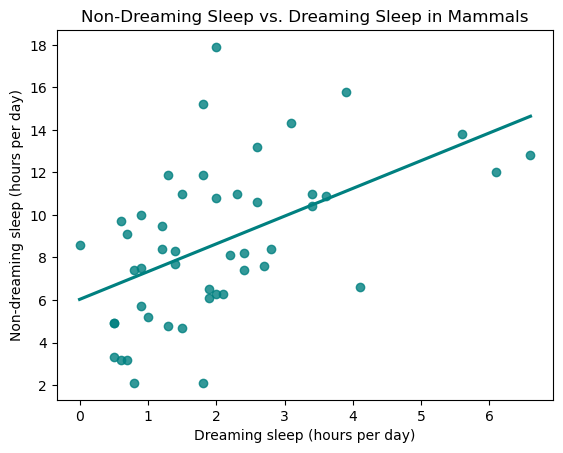

In [9]:
# Plot dreaming sleep and non-dreaming sleep.
sns.regplot(data=sleep_df, x="dreaming_sleep", y="non_dreaming_sleep", ci=None, color="teal")
plt.title("Non-Dreaming Sleep vs. Dreaming Sleep in Mammals")
plt.xlabel("Dreaming sleep (hours per day)")
plt.ylabel("Non-dreaming sleep (hours per day)")
plt.show()

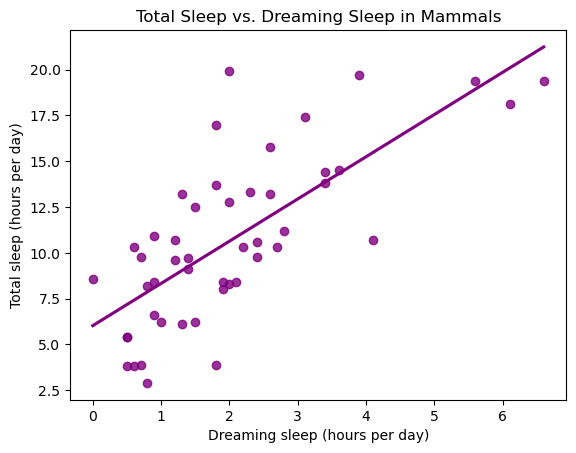

In [10]:
# Plot dreaming sleep and total sleep.
sns.regplot(data=sleep_df, x="dreaming_sleep", y="total_sleep", ci=None, color="purple")
plt.title("Total Sleep vs. Dreaming Sleep in Mammals")
plt.xlabel("Dreaming sleep (hours per day)")
plt.ylabel("Total sleep (hours per day)")
plt.show()

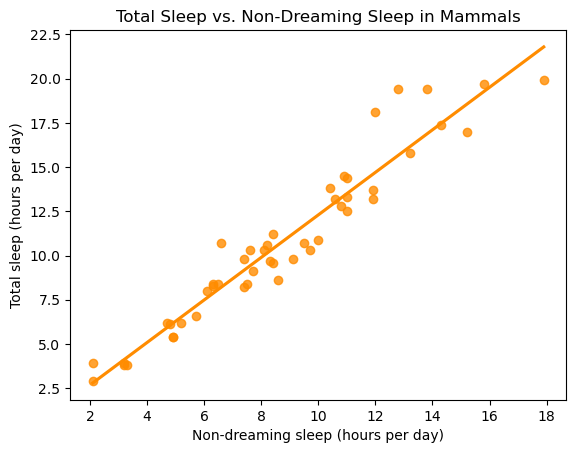

In [11]:
# Plot non-dreaming sleep and total sleep.
sns.regplot(data=sleep_df, x="non_dreaming_sleep", y="total_sleep", ci=None, color="darkorange")
plt.title("Total Sleep vs. Non-Dreaming Sleep in Mammals")
plt.xlabel("Non-dreaming sleep (hours per day)")
plt.ylabel("Total sleep (hours per day)")
plt.show()

In [12]:
# Calculate all three correlations and R-squared values.
sleep_corr = sleep_df[["dreaming_sleep", "non_dreaming_sleep", "total_sleep"]].corr()

sleep_summary = pd.DataFrame({
    "correlation": [
        sleep_corr.loc["dreaming_sleep", "non_dreaming_sleep"],
        sleep_corr.loc["dreaming_sleep", "total_sleep"],
        sleep_corr.loc["non_dreaming_sleep", "total_sleep"]
    ]
}, index=["Dreaming vs. non-dreaming", "Dreaming vs. total", "Non-dreaming vs. total"])
sleep_summary["r_squared"] = sleep_summary["correlation"] ** 2

sleep_summary.round(3)

,correlation,r_squared
Dreaming vs. non-dreaming,0.514,0.264
Dreaming vs. total,0.727,0.529
Non-dreaming vs. total,0.963,0.927


**For each plot, do the points generally rise or fall? Is their pattern roughly straight or curved, and how closely do they follow it? Identify any unusual observations. Which plot is best summarized by a straight line? Explain what its R-squared tells you about total sleep.**

Your answer:

- **Non-dreaming vs. dreaming:** The points generally rise from left to right, but the pattern is loose. It is roughly straight with a lot of scatter around the line (r = 0.514, R-squared = 0.264). Unusual points include the Echidna, which has 0.0 hours of dreaming sleep but 8.6 hours of non-dreaming sleep, the Little brown bat with 17.9 hours of non-dreaming sleep but only 2.0 hours of dreaming, and the Water opossum and Giant armadillo, which have much more dreaming sleep (6.6 and 6.1 hours) than the others.
- **Total vs. dreaming:** The points rise and follow a roughly straight pattern, but they are still spread out moderately around the line (r = 0.727, R-squared = 0.529). Species with similar dreaming sleep can have very different total sleep. The Water opossum and Giant armadillo are far to the right, and the Echidna sits alone at 0 dreaming hours.
- **Total vs. non-dreaming:** The points rise and follow a straight pattern very closely (r = 0.963, R-squared = 0.927). Nothing is far from the overall pattern, but the Water opossum and Giant armadillo sit noticeably above the line because they have a lot of dreaming sleep for their amount of non-dreaming sleep.

The non-dreaming vs. total plot is best summarized by a straight line. Its R-squared of 0.927 means about 93% of the variation in total sleep (hours per day) among these 48 species is accounted for by a straight line on non-dreaming sleep, and about 7% of the variation remains around the line. Most of that remaining variation comes from differences in dreaming sleep.

## Step 4: Check

Check that `dreaming_sleep + non_dreaming_sleep` agrees with `total_sleep` using `np.isclose()`, which allows for ordinary floating-point rounding. Display several original rows with their phase sum. Then display the three records with the longest non-dreaming sleep and locate their points on the non-dreaming versus total sleep plot. Do the plotted values agree with the records?

In [13]:
# Check the sleep-phase sum and display original measurements.
phase_sum = sleep_df["dreaming_sleep"] + sleep_df["non_dreaming_sleep"]
phase_matches = np.isclose(phase_sum, sleep_df["total_sleep"])

print("Rows where the phases add up to total sleep:", phase_matches.sum(), "of", len(sleep_df))

sleep_df[["species", "dreaming_sleep", "non_dreaming_sleep", "total_sleep"]].assign(phase_sum=phase_sum).head(8)

Rows where the phases add up to total sleep: 48 of 48


,species,dreaming_sleep,non_dreaming_sleep,total_sleep,phase_sum
1,African giant pouched rat,2.0,6.3,8.3,8.3
4,Asian elephant,1.8,2.1,3.9,3.9
5,Baboon,0.7,9.1,9.8,9.8
6,Big brown bat,3.9,15.8,19.7,19.7
7,Brazilian tapir,1.0,5.2,6.2,6.2
8,Cat,3.6,10.9,14.5,14.5
9,Chimpanzee,1.4,8.3,9.7,9.7
10,Chinchilla,1.5,11.0,12.5,12.5


In [14]:
# Inspect the three records with the longest non-dreaming sleep.
sleep_df.nlargest(3, "non_dreaming_sleep")[["species", "dreaming_sleep", "non_dreaming_sleep", "total_sleep"]]

,species,dreaming_sleep,non_dreaming_sleep,total_sleep
32,Little brown bat,2.0,17.9,19.9
6,Big brown bat,3.9,15.8,19.7
41,Owl monkey,1.8,15.2,17.0


## Step 5: Conclusion

**Research question:** How are dreaming and non-dreaming sleep related, and which phase has the stronger linear relationship with total sleep?

**Do mammals that spend more time in dreaming sleep also tend to spend more time in non-dreaming sleep? Which phase is more strongly related to total sleep? Support your answers with the plots, correlations, and R-squared values. Did the results match your prediction?**

Your answer: Yes, but only loosely. Mammals with more dreaming sleep tend to also have more non-dreaming sleep, but the points are widely scattered (r = 0.514, R-squared = 0.264), so a straight line on dreaming sleep accounts for only about 26% of the variation in non-dreaming sleep. Species like the Echidna (0 hours of dreaming, 8.6 hours of non-dreaming) and the Little brown bat (2.0 hours of dreaming, 17.9 hours of non-dreaming) show that knowing one phase does not pin down the other.

Non-dreaming sleep is much more strongly related to total sleep. The non-dreaming vs. total plot follows a straight line very closely (r = 0.963, R-squared = 0.927), while the dreaming vs. total plot is more spread out (r = 0.727, R-squared = 0.529). The check confirmed that the two phases add up to total sleep in all 48 records, and the three longest non-dreaming sleepers (Little brown bat, Big brown bat, Owl monkey) appear where expected at the top right of the plot. This matched my prediction: all three relationships were positive, and non-dreaming sleep was the stronger one because it makes up most of each animal's total sleep.

## Step 6: Limitation

**State two limitations specific to these sleep relationships. Explain why a stronger correlation is not automatically a better scientific explanation.**

Your answer:

1. Total sleep is defined as dreaming plus non-dreaming sleep, so the strong relationship between non-dreaming and total sleep is partly built in. Non-dreaming sleep is the larger part of the sum, so it will track the total closely almost automatically. It does not tell us anything new about why some mammals sleep more.
2. The data come from a historical 1976 study of 48 species with complete records, not a random sample of all mammals. Each row is a species-level value, so the results may not apply to other species, to individual animals, or to measurements made with modern methods. The 14 removed species were missing sleep-phase measurements, so they might differ from the ones we kept.

A stronger correlation is not automatically a better scientific explanation because correlation only measures how closely points follow a straight line. Here the 0.963 correlation is high mainly because total sleep contains non-dreaming sleep, not because non-dreaming sleep causes or explains total sleep. A correlation also does not show cause and effect, and it does not tell us how well the line would work for species outside this dataset.

# Investigation 2: Do danger and predation add information?

## Step 1: Question

**Do danger and predation categories add information about total sleep beyond non-dreaming sleep?**

**Predict whether each index will add substantial, small, or little visible information. What would you look for at comparable non-dreaming-sleep durations?**

Your answer: I predict both indices will add only a small amount of information. Non-dreaming sleep already accounts for about 93% of the variation in total sleep, so there is only about 7% left to explain, and most of that comes from dreaming sleep. If animals in more danger get less dreaming sleep, danger might add a little. I expect danger to add slightly more than predation, because the danger index already includes predation along with other information.

At comparable non-dreaming sleep durations, I would look for whether the points and lines for different rating levels sit at different heights. If the higher-danger or higher-predation groups are consistently lower on total sleep at the same non-dreaming sleep, the index adds information. If the groups overlap, it adds little.

## Step 2: Data

Reuse `sleep_df` and its original sleep measurements. Count records for each danger and predation rating and display a cross-tabulation of the two indices. Keep all five original levels in their natural order. Higher predation index values mean a mammal is more likely to be preyed upon. Higher danger index values mean greater overall danger from other animals.

In [15]:
# Count the records at each danger and predation level.
print(sleep_df["danger_index"].value_counts().sort_index())
print()
print(sleep_df["predation_index"].value_counts().sort_index())

danger_index
1    14
2    12
3     8
4     9
5     5
Name: count, dtype: int64

predation_index
1    10
2    13
3     9
4     7
5     9
Name: count, dtype: int64


In [16]:
# Cross-tabulate danger and predation ratings.
pd.crosstab(sleep_df["danger_index"], sleep_df["predation_index"])

predation_index,1,2,3,4,5
danger_index,,,,,
1,10,4,0,0,0
2,0,9,3,0,0
3,0,0,5,2,1
4,0,0,1,5,3
5,0,0,0,0,5


## Step 3: Evidence

Use `sns.lmplot()` twice on the non-dreaming–total sleep relationship, once colored by `danger_index` and once by `predation_index`. Set `hue_order=[1, 2, 3, 4, 5]`, use a named palette, and label the legend so the index direction is clear. The separate lines show group patterns; small groups may produce unstable lines. Compare groups where their non-dreaming-sleep ranges overlap.

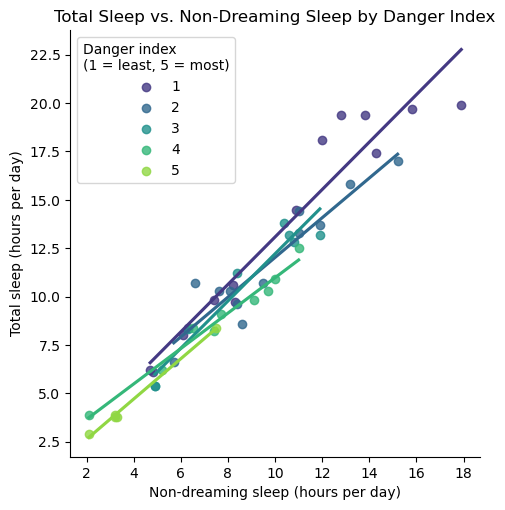

In [17]:
# Plot the non-dreaming–total sleep relationship by danger category.
sns.lmplot(
    data=sleep_df,
    x="non_dreaming_sleep",
    y="total_sleep",
    hue="danger_index",
    hue_order=[1, 2, 3, 4, 5],
    palette="viridis",
    ci=None,
    legend=False
)
plt.title("Total Sleep vs. Non-Dreaming Sleep by Danger Index")
plt.xlabel("Non-dreaming sleep (hours per day)")
plt.ylabel("Total sleep (hours per day)")
plt.legend(title="Danger index\n(1 = least, 5 = most)")
plt.show()

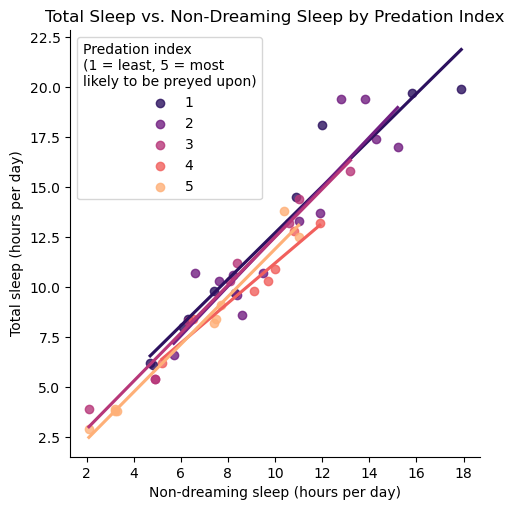

In [18]:
# Plot the non-dreaming–total sleep relationship by predation category.
sns.lmplot(
    data=sleep_df,
    x="non_dreaming_sleep",
    y="total_sleep",
    hue="predation_index",
    hue_order=[1, 2, 3, 4, 5],
    palette="magma",
    ci=None,
    legend=False
)
plt.title("Total Sleep vs. Non-Dreaming Sleep by Predation Index")
plt.xlabel("Non-dreaming sleep (hours per day)")
plt.ylabel("Total sleep (hours per day)")
plt.legend(title="Predation index\n(1 = least, 5 = most\nlikely to be preyed upon)")
plt.show()

**Describe overlap and separation in each plot. How do the group sizes and available non-dreaming-sleep ranges affect your interpretation?**

Your answer:

**Danger plot:** The groups overlap a lot. Between about 5 and 11 hours of non-dreaming sleep, points from all five danger levels are mixed together along the same upward band. The danger 1 line sits slightly above the others, so the least-endangered species tend to have a little more total sleep at the same non-dreaming sleep. The danger 2–5 lines are close together and cross each other, so there is no clear step-by-step separation.

**Predation plot:** The overlap is even greater. Most of the predation lines lie almost on top of each other. The predation 1 and 2 lines are slightly higher at longer non-dreaming sleep, and the predation 4 and 5 lines are slightly lower, but the points from different levels are thoroughly mixed.

**Group sizes and ranges:** Some groups are small. Danger 5 has only 5 species, and predation 4 has only 7, so their lines could change a lot if one point were different. The groups also cover different non-dreaming ranges. Danger 1 runs from 4.7 to 17.9 hours, while danger 5 only runs from 2.1 to 7.5 hours. The long stretch of the danger 1 line above 12 hours has no other danger groups to compare with, so differences there are not a fair comparison. I can only compare lines where the groups actually have observations at similar non-dreaming sleep, which is mostly the 5 to 11 hour range.

### Compare model R-squared

The supplied helper follows the lecture's least-squares calculation. Read and run it; you do not need to recreate its matrix operations. `pd.get_dummies()` represents each rating with category indicators. `drop_first=True` chooses a reference level. This avoids assuming equal distances between index values.

These are **additive models**: one shared slope for the quantitative predictor and category-specific intercept adjustments. They differ from the separate group slopes in `lmplot()`. Compare the baseline, baseline plus danger, baseline plus predation, and baseline plus both, all on identical rows and the same response scale. Training R-squared cannot decrease when predictors are added to these nested models; an increase alone does not establish improved performance on new observations.

In [19]:
def calculate_r_squared(data, predictor, response, categorical_features):
    predictors = pd.get_dummies(
        data[[predictor, *categorical_features]],
        columns=categorical_features, drop_first=True, dtype=float
    )
    predictors.insert(0, "intercept", 1.0)
    x = predictors.to_numpy(dtype=float)
    y = data[response].to_numpy(dtype=float)
    fitted = x @ np.linalg.lstsq(x, y, rcond=None)[0]
    return 1 - ((y - fitted) ** 2).sum() / ((y - y.mean()) ** 2).sum()

In [20]:
# Build and display phase_comparison for the four models.
phase_comparison = pd.Series(
    {
        "Non-dreaming only": calculate_r_squared(
            sleep_df, "non_dreaming_sleep", "total_sleep", []
        ),
        "Non-dreaming + danger": calculate_r_squared(
            sleep_df, "non_dreaming_sleep", "total_sleep", ["danger_index"]
        ),
        "Non-dreaming + predation": calculate_r_squared(
            sleep_df, "non_dreaming_sleep", "total_sleep", ["predation_index"]
        ),
        "Non-dreaming + both": calculate_r_squared(
            sleep_df, "non_dreaming_sleep", "total_sleep", ["danger_index", "predation_index"]
        )
    },
    name="r_squared"
)

phase_comparison.round(3)

Non-dreaming only           0.927
Non-dreaming + danger       0.943
Non-dreaming + predation    0.937
Non-dreaming + both         0.951
Name: r_squared, dtype: float64

## Step 4: Check

For each danger rating, display the smallest and largest non-dreaming sleep values using `.groupby()` and `.agg(["min", "max"])`. Repeat for predation ratings.

Compare these ranges with the group plots. Use the ranges to identify where two groups actually have observations at similar non-dreaming sleep durations.

In [21]:
# Display the non-dreaming sleep range for each danger and predation rating.
print(sleep_df.groupby("danger_index")["non_dreaming_sleep"].agg(["min", "max"]))
print()
print(sleep_df.groupby("predation_index")["non_dreaming_sleep"].agg(["min", "max"]))

              min   max
danger_index           
1             4.7  17.9
2             5.7  15.2
3             4.9  11.9
4             2.1  11.0
5             2.1   7.5

                 min   max
predation_index           
1                4.7  17.9
2                5.7  15.2
3                2.1  13.2
4                5.2  11.9
5                2.1  11.0


**Choose two danger groups. Over what range of non-dreaming sleep do both groups have observations? Why should you compare their lines within that shared range?**

Your answer: I chose danger 1 and danger 5. Danger 1 has non-dreaming sleep from 4.7 to 17.9 hours, and danger 5 has non-dreaming sleep from 2.1 to 7.5 hours. Both groups only have observations between 4.7 and 7.5 hours of non-dreaming sleep, which is a pretty narrow window.

I should compare their lines only within that shared range because outside it, one of the lines is being drawn where that group has no data. The danger 1 line above 7.5 hours has no danger 5 species to compare against, and the danger 5 line below 4.7 hours has no danger 1 species. A gap between the lines there would just come from extending a line past its data, not from an actual difference between species with similar non-dreaming sleep. With only 5 species in danger 5, even the comparison inside the shared range is based on very few points.

## Step 5: Conclusion

**Research question:** Do danger and predation categories add information about total sleep beyond non-dreaming sleep?

**Does adding danger, predation, or both improve the model of total sleep? Report the four R-squared values and how much each changes from non-dreaming sleep alone. Are the improvements small or large? Explain how the group plots support your answer.**

Your answer: Adding the indices improves the fit only slightly. The four R-squared values are:

- Non-dreaming sleep only: 0.927
- Non-dreaming + danger: 0.943 (an increase of 0.016)
- Non-dreaming + predation: 0.937 (an increase of 0.010)
- Non-dreaming + both: 0.951 (an increase of 0.024)

These are small improvements. Non-dreaming sleep alone already accounts for about 93% of the variation in total sleep, and adding both indices raises that to about 95%. Danger adds a little more than predation, which matches my prediction. Adding both adds less than the two separate increases combined (0.024 vs. 0.026), which makes sense because the cross-tabulation showed the two ratings mostly line up with each other.

The group plots support this. In both plots the points from different rating levels are mixed together along the same upward band. The only visible pattern is that the lowest-danger and lowest-predation lines sit slightly above the highest ones at the same non-dreaming sleep, which fits with the small R-squared gains. Since R-squared can never go down when categories are added to these models, a small increase like this does not prove that danger or predation would improve predictions for new species.

## Step 6: Limitation

**Identify two limitations of this investigation.**

Your answer:

1. The groups are small and cover different ranges of non-dreaming sleep. Danger 5 has only 5 species and predation 4 only 7, and some groups only overlap in narrow ranges, so the group lines and the category adjustments in the models could change a lot with a few different species.
2. These R-squared values measure fit to the same 48 species the models were built on, not performance on new species. The danger and predation ratings are also ordinal ratings assigned in a historical study, not direct measurements of risk, and the data are observational, so even a better fit would not show that danger or predation causes mammals to sleep less.

# Investigation 3: Gestation time and total sleep

## Step 1: Question

**How is total sleep related to gestation time, and do danger and predation add information about sleep after accounting for gestation time?**

Gestation time is the length of a pregnancy, measured in days. We will compare it with total sleep, measured in hours per day, and see whether taking the logarithm of gestation time makes the pattern look straighter.

**Do you expect mammals with longer pregnancies to sleep more hours per day, fewer hours, or about the same amount? Explain your initial guess. You do not need prior knowledge about mammals; you will compare your prediction with the data.**

Your answer: I expect mammals with longer pregnancies to sleep fewer hours per day. Long pregnancies usually belong to larger animals like elephants, horses, and giraffes, and I think of those as animals that stay awake and alert more, often because they graze for long hours or need to watch for predators. Small animals with short pregnancies, like rodents and bats, seem like they would sleep more. I expect a downward relationship that is not very tight, since animals with similar gestation times probably still vary a lot in how much they sleep.

## Step 2: Data

Create `gestation_df` by dropping rows missing `gestation_time`, `total_sleep`, `danger_index`, or `predation_index`, then copying the result. How many records were removed from the dataset? Do not drop rows merely because maximum lifespan is missing. Check that gestation is positive and sleep is between 0 and 24 hours per day. Create `log10_gestation_time` only after checking the inputs.

In [22]:
# Prepare gestation_df and check counts and plausible ranges.
gestation_df = mammals_df.dropna(
    subset=["gestation_time", "total_sleep", "danger_index", "predation_index"]
).copy()

print("Records in mammals_df:", len(mammals_df))
print("Records in gestation_df:", len(gestation_df))
print("Records removed:", len(mammals_df) - len(gestation_df))
print("All gestation times positive:", (gestation_df["gestation_time"] > 0).all())
print("All total sleep between 0 and 24:", gestation_df["total_sleep"].between(0, 24).all())

gestation_df["log10_gestation_time"] = np.log10(gestation_df["gestation_time"])

gestation_df[["gestation_time", "log10_gestation_time", "total_sleep"]].agg(["min", "max"])

Records in mammals_df: 62
Records in gestation_df: 54
Records removed: 8
All gestation times positive: True
All total sleep between 0 and 24: True


,gestation_time,log10_gestation_time,total_sleep
min,12.0,1.079181,2.6
max,645.0,2.809560,19.9


## Step 3: Evidence

Plot sleep against gestation on original scales, then against log10 gestation, leaving sleep in hours per day. Calculate correlation and simple-line R-squared for each. These R-squared values share the same response scale and observations. Compare whether the points follow a straight or curved pattern and how widely they are scattered, as well as the numerical summaries.

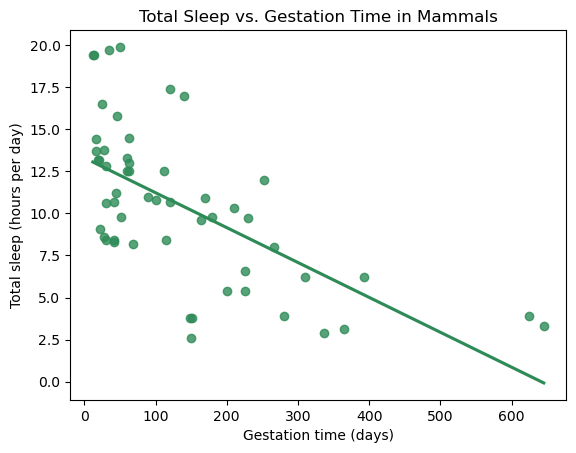

In [23]:
# Plot original gestation and sleep.
sns.regplot(data=gestation_df, x="gestation_time", y="total_sleep", ci=None, color="seagreen")
plt.title("Total Sleep vs. Gestation Time in Mammals")
plt.xlabel("Gestation time (days)")
plt.ylabel("Total sleep (hours per day)")
plt.show()

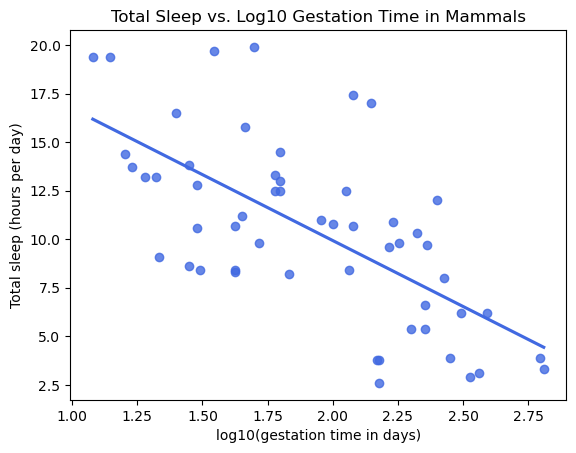

In [24]:
# Plot log gestation and sleep.
sns.regplot(data=gestation_df, x="log10_gestation_time", y="total_sleep", ci=None, color="royalblue")
plt.title("Total Sleep vs. Log10 Gestation Time in Mammals")
plt.xlabel("log10(gestation time in days)")
plt.ylabel("Total sleep (hours per day)")
plt.show()

In [25]:
# Calculate the two correlations and squared correlations.
gestation_corr = gestation_df[["gestation_time", "log10_gestation_time", "total_sleep"]].corr()

gestation_summary = pd.DataFrame({
    "correlation": [
        gestation_corr.loc["gestation_time", "total_sleep"],
        gestation_corr.loc["log10_gestation_time", "total_sleep"]
    ]
}, index=["Gestation vs. total sleep", "Log10 gestation vs. total sleep"])
gestation_summary["r_squared"] = gestation_summary["correlation"] ** 2

gestation_summary.round(3)

,correlation,r_squared
Gestation vs. total sleep,-0.631,0.399
Log10 gestation vs. total sleep,-0.664,0.440


**What changes when gestation is log-transformed? Does the transformation remove the scatter or only improve the straight-line summary modestly?**

Your answer: On the original scale, total sleep falls as gestation time increases, but the pattern is curved. Most species are bunched on the left with gestation under about 150 days, where sleep ranges widely from about 8 to 20 hours. Sleep drops quickly over the first couple hundred days and then levels off around 3 to 6 hours for the long-gestation species. The straight line misses this curve. It keeps dropping and predicts almost 0 hours of sleep at 645 days, but the African and Asian elephants actually sleep 3.3 and 3.9 hours. The correlation is -0.631 and R-squared is 0.399.

After the log transformation, the points are spread more evenly across the horizontal axis and the downward pattern looks roughly straight, so the line follows the points better at both ends. The correlation strengthens to -0.664 and R-squared rises to 0.440, so the line on log gestation accounts for about 44% of the variation in total sleep compared with about 40% on the original scale.

The transformation does not remove the scatter. Species with similar log gestation still differ by many hours of sleep. For example, around 1.5 to 1.7 the points range from about 8 to 20 hours. About 56% of the variation in total sleep remains, so the log scale only modestly improves the straight-line summary.

Reuse the group-plot and model-comparison approach from Investigation 2, now using `log10_gestation_time` as the predictor and `total_sleep` as the response. Count observations at each rating level in this subset before interpreting the group lines. Examine danger and predation separately, then compare all four additive models on `gestation_df`.

In [26]:
# Count ratings in the sleep subset.
print(gestation_df["danger_index"].value_counts().sort_index())
print()
print(gestation_df["predation_index"].value_counts().sort_index())

danger_index
1    16
2    12
3    10
4     9
5     7
Name: count, dtype: int64

predation_index
1    12
2    14
3     9
4     7
5    12
Name: count, dtype: int64


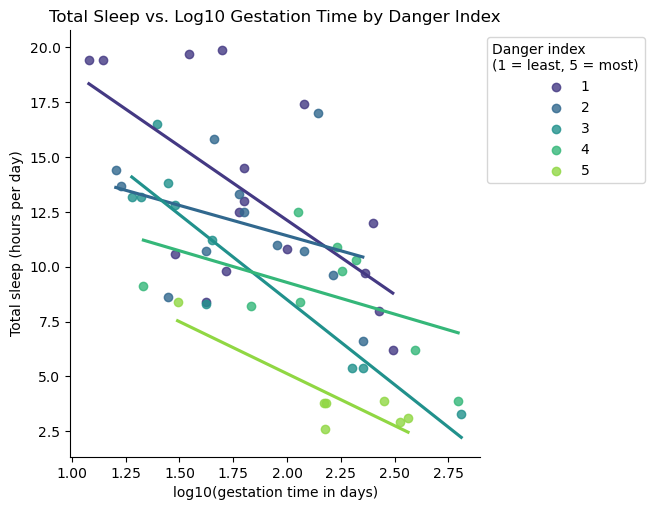

In [27]:
# Plot log gestation and sleep by danger.
sns.lmplot(
    data=gestation_df,
    x="log10_gestation_time",
    y="total_sleep",
    hue="danger_index",
    hue_order=[1, 2, 3, 4, 5],
    palette="viridis",
    ci=None,
    legend=False
)
plt.title("Total Sleep vs. Log10 Gestation Time by Danger Index")
plt.xlabel("log10(gestation time in days)")
plt.ylabel("Total sleep (hours per day)")
plt.legend(title="Danger index\n(1 = least, 5 = most)", loc="upper left", bbox_to_anchor=(1, 1))
plt.show()

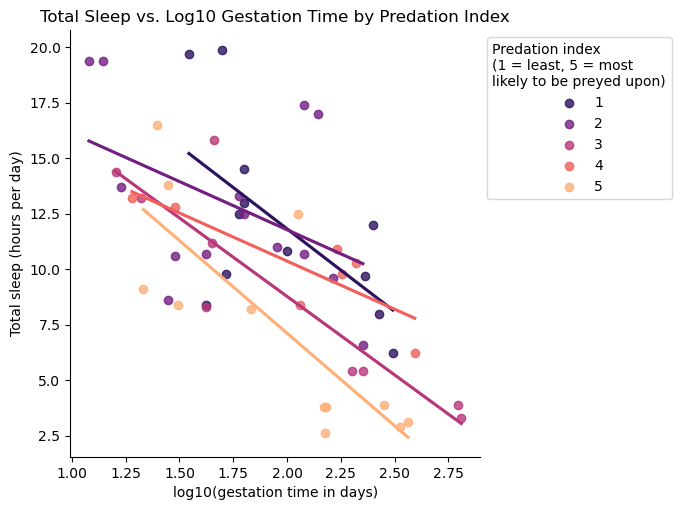

In [28]:
# Plot log gestation and sleep by predation.
sns.lmplot(
    data=gestation_df,
    x="log10_gestation_time",
    y="total_sleep",
    hue="predation_index",
    hue_order=[1, 2, 3, 4, 5],
    palette="magma",
    ci=None,
    legend=False
)
plt.title("Total Sleep vs. Log10 Gestation Time by Predation Index")
plt.xlabel("log10(gestation time in days)")
plt.ylabel("Total sleep (hours per day)")
plt.legend(title="Predation index\n(1 = least, 5 = most\nlikely to be preyed upon)", loc="upper left", bbox_to_anchor=(1, 1))
plt.show()

In [29]:
# Build and display sleep_comparison for the four models.
sleep_comparison = pd.Series(
    {
        "Log gestation only": calculate_r_squared(
            gestation_df, "log10_gestation_time", "total_sleep", []
        ),
        "Log gestation + danger": calculate_r_squared(
            gestation_df, "log10_gestation_time", "total_sleep", ["danger_index"]
        ),
        "Log gestation + predation": calculate_r_squared(
            gestation_df, "log10_gestation_time", "total_sleep", ["predation_index"]
        ),
        "Log gestation + both": calculate_r_squared(
            gestation_df, "log10_gestation_time", "total_sleep", ["danger_index", "predation_index"]
        )
    },
    name="r_squared"
)

sleep_comparison.round(3)

Log gestation only           0.440
Log gestation + danger       0.654
Log gestation + predation    0.592
Log gestation + both         0.694
Name: r_squared, dtype: float64

## Step 4: Check

For the first five records, display gestation time, its logarithm, and `10 ** log10_gestation_time`. Does reversing the logarithm recover the original number of days?

Display the records with the shortest and longest gestation times. Find their points in both plots and compare the recorded sleep hours with their vertical positions. The horizontal positions change when gestation is transformed; the sleep measurements stay the same.

In [30]:
# Reverse the logarithm for five records and compare with the original gestation times.
gestation_df[["species", "gestation_time", "log10_gestation_time"]].assign(
    reversed_gestation=10 ** gestation_df["log10_gestation_time"]
).head()

,species,gestation_time,log10_gestation_time,reversed_gestation
0,African elephant,645.0,2.809560,645.0
1,African giant pouched rat,42.0,1.623249,42.0
2,Arctic Fox,60.0,1.778151,60.0
3,Arctic ground squirrel,25.0,1.397940,25.0
4,Asian elephant,624.0,2.795185,624.0


In [31]:
# Inspect extreme gestation records.
extreme_rows = [gestation_df["gestation_time"].idxmin(), gestation_df["gestation_time"].idxmax()]
gestation_df.loc[extreme_rows, ["species", "gestation_time", "log10_gestation_time", "total_sleep"]]

,species,gestation_time,log10_gestation_time,total_sleep
38,N. American opossum,12.0,1.079181,19.4
0,African elephant,645.0,2.809560,3.3


**Did reversing the logarithm recover the original gestation times? For the shortest and longest gestation records, do both plots show the recorded total sleep values? Describe what changed between the plots and what stayed the same.**

Your answer: Yes. For the first five records, 10 raised to the log10 gestation time gave back the original values (645, 42, 60, 25, and 624 days), so the transformation was done correctly and can be reversed.

The shortest gestation is the N. American opossum at 12 days (log10 = 1.08) with 19.4 hours of total sleep, and the longest is the African elephant at 645 days (log10 = 2.81) with 3.3 hours of total sleep. In both plots, the opossum is the point at the far left near the top at about 19.4 hours, and the elephant is the point at the far right near the bottom at about 3.3 hours, so both plots show the recorded sleep values.

What changed between the plots is the horizontal position. On the original scale, the elephant is far away from the rest of the points at 645 days, and the opossum is squeezed in with many other short-gestation species near the left edge. On the log scale, the points are spread more evenly, and the elephant is much closer to the other long-gestation species. What stayed the same is the vertical position, because total sleep was not transformed and is still in hours per day.

## Step 5: Conclusion

**Research question:** How is total sleep related to gestation time, and do danger and predation add information about sleep after accounting for gestation time?

**Do mammals with longer gestation times tend to sleep more or less? Does using log gestation make the pattern look straighter? Do danger and predation add information? Support your answers with the plots, correlation, and R-squared values, and compare the results with your prediction.**

Your answer: Mammals with longer gestation times tend to sleep less. Both plots show a downward pattern, with a correlation of -0.631 on the original scale and -0.664 on the log scale. Short-gestation species like the N. American opossum (12 days, 19.4 hours) sleep a lot, while long-gestation species like the African elephant (645 days, 3.3 hours) sleep very little. This matched my prediction of a downward and fairly loose relationship.

Using log gestation makes the pattern look straighter. On the original scale the points curve, dropping quickly and then leveling off, and the line predicts almost 0 hours for the elephants. On the log scale the points are spread more evenly and follow a roughly straight downward trend. R-squared only rises from 0.399 to 0.440, though, so the log scale improves the straight-line summary modestly, and a lot of scatter remains.

Unlike in Investigation 2, danger and predation add a lot of information here. The R-squared values are:

- Log gestation only: 0.440
- Log gestation + danger: 0.654 (an increase of 0.214)
- Log gestation + predation: 0.592 (an increase of 0.152)
- Log gestation + both: 0.694 (an increase of 0.254)

The danger plot shows this clearly. At similar log gestation times, the danger 5 species sit lowest, between 2.6 and 8.4 hours of sleep, and the danger 1 species are mostly the highest. The predation plot shows a similar but less clean separation, with the predation 5 line the lowest. Danger adds more than predation, and adding both adds only a little more than danger alone because the two ratings overlap. This is a much bigger gain than in Investigation 2 because log gestation leaves about 56% of the variation unexplained, so there is much more room for the ratings to add information.

## Step 6: Limitation

**Identify two limitations of the gestation and sleep investigation.**

Your answer:

1. The groups are small and do not cover the same gestation ranges. Danger 5 has only 7 species and predation 4 only 7, and the separate group lines in the plots have different slopes that could change a lot with a few different species. The additive models use one shared slope, so they also do not match the group lines exactly.
2. The R-squared values describe how well the models fit these same 54 species, not how well they would predict sleep for new species. The data are observational and come from a 1976 study that is not a random sample of mammals. Gestation time is also linked to body size, and danger is linked to things like being a large grazing animal, so the higher R-squared does not show that longer pregnancies or greater danger cause mammals to sleep less.

## AI-use reflection

**Did you use AI? If so, describe one suggestion you checked against your source, code, or output and what you accepted, modified, or rejected. If not, state that you did not use it.**

Your answer: Yes. I used Claude (an AI assistant) to help write the code and draft the written answers. One suggestion I checked was where to put the legends on the two Investigation 3 group plots (total sleep vs. log10 gestation by danger and by predation). The default legend in the top right covered some of the points, and the first suggestion was to move it to the lower-left corner. When I looked at the plots, the lower-left legend covered even more points, so I rejected that and modified the code to place the legend outside the plot area with `loc="upper left", bbox_to_anchor=(1, 1)`, so no points are hidden. I also checked the calculated values against the output, for example that the dreaming and non-dreaming phases add up to total sleep in all 48 records and that reversing the log recovers the original gestation times.

## Submission checklist

- Use the supplied CSV with a relative path.
- Complete the dictionary table and every written response.
- Include a prediction and all six workflow steps for each investigation.
- Include all three sleep comparison plots, two non-dreaming–total group plots, original and log-gestation sleep plots, and two sleep group plots.
- Keep observations consistent within each comparison; report counts and investigate exclusions.
- Interpret correlation and R-squared on the correct scale, using numerical and visual evidence.
- Compare baseline, danger, predation, and combined models without claiming automatic causal or predictive improvement.
- Explain whether the patterns are straight or curved, how the log transformation changes the gestation plot, and what the analyses cannot tell us.
- Complete the AI-use reflection, restart the kernel, and run the notebook in order before submitting.